# Assignment_2: Q2

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 15)

RAW_PATH = Path("raw_dataset") / "diabetes.csv"
PROCESSED_PATH = Path("processed_dataset") / "diabetes_processed.csv"
OUTPUT_DIR = Path("output")

SEED = 42
POPULATION_COLOR = "#0073ff"
SAMPLE_COLOR = "#ff0000"

print("pandas version:", pd.__version__)

pandas version: 3.0.5


## 2. Preprocessing

### Load the raw data

In [2]:
raw_diabetes = pd.read_csv(RAW_PATH)

print("shape:", raw_diabetes.shape)

shape: (768, 9)


In [3]:
raw_diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
raw_diabetes.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


### Check for missing values and duplicate

In [5]:
print("Missing values:", int(raw_diabetes.isna().sum().sum()))
print("Duplicate rows:", int(raw_diabetes.duplicated().sum()))

Missing values: 0
Duplicate rows: 0


### Check for the Zero values

In [6]:
zero_report = pd.DataFrame({
    "zero_count": (raw_diabetes == 0).sum(),
    "zero_percent": ((raw_diabetes == 0).mean() * 100).round(2),
})

zero_report

,zero_count,zero_percent
Pregnancies,111,14.45
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43
DiabetesPedigreeFunction,0,0.00
Age,0,0.00
Outcome,500,65.10


1. For rows `Glucose`, `BloodPressure`, and `BMI`(Values = 0), I will drop them becasue filling in 35 missing blood pressure values with the same value would artificially reduce the range of the data distribution.
2. For `SkinThickness` and `Insulin` (Values = 0), I will mark as missing and keep them. Becasue as many as 49% of the values are invalid. If these rows are deleted, half of the data sample will be lost. If these values are interpolated, half of the columns will be fake data. Since neither of these variables is used, they are retained as genuine `NaN` values.

In [7]:
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
ANALYSIS_COLUMNS = ["Glucose", "BloodPressure", "BMI"]

diabetes = raw_diabetes.copy()
diabetes[ZERO_AS_MISSING] = diabetes[ZERO_AS_MISSING].replace(0, np.nan)

diabetes.isna().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [8]:
rows_before = len(diabetes)
diabetes = diabetes.dropna(subset=ANALYSIS_COLUMNS).reset_index(drop=True)

print("Rows before:", rows_before)
print("Rows after: ", len(diabetes))
print("Rows dropped:", rows_before - len(diabetes))

Rows before: 768
Rows after:  724
Rows dropped: 44


### Double check

In [9]:
median_imputed = raw_diabetes[ANALYSIS_COLUMNS].replace(0, np.nan)
median_imputed = median_imputed.fillna(median_imputed.median())

cleaning_effect = pd.DataFrame({
    "raw_mean": raw_diabetes[ANALYSIS_COLUMNS].mean(),
    "clean_mean": diabetes[ANALYSIS_COLUMNS].mean(),
    "raw_std": raw_diabetes[ANALYSIS_COLUMNS].std(ddof=0),
    "clean_std": diabetes[ANALYSIS_COLUMNS].std(ddof=0),
    "median_imputed_std": median_imputed.std(ddof=0),
}).round(2)

cleaning_effect

,raw_mean,clean_mean,raw_std,clean_std,median_imputed_std
Glucose,120.89,121.88,31.95,30.73,30.42
BloodPressure,69.11,72.40,19.34,12.37,12.09
BMI,31.99,32.47,7.88,6.88,6.87


### Export

In [10]:
diabetes.to_csv(PROCESSED_PATH, index=False)

print("Exported:", PROCESSED_PATH.resolve())

Exported: D:\Assignment_2\Q2\processed_dataset\diabetes_processed.csv


## 3. Part (a)

### Load the population

In [11]:
population = pd.read_csv(PROCESSED_PATH)

print("Population size:", len(population))

Population size: 724


### Draw the sample

In [12]:
sample_25 = population.sample(n=25, random_state=SEED)

print("Sample size:", len(sample_25))
sample_25.head()

Sample size: 25


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
326,1,139.0,46.0,19.0,83.0,28.7,0.654,22,0
518,1,88.0,62.0,24.0,44.0,29.9,0.422,23,0
554,11,111.0,84.0,40.0,NaN,46.8,0.925,45,1
33,11,138.0,76.0,NaN,NaN,33.2,0.420,35,0
375,3,193.0,70.0,31.0,NaN,34.9,0.241,25,1


### Compare mean and highest Glucose

In [13]:
glucose_comparison = pd.DataFrame(
    {
        "population": [population["Glucose"].mean(), population["Glucose"].max()],
        "sample": [sample_25["Glucose"].mean(), sample_25["Glucose"].max()],
    },
    index=["mean", "maximum"],
)
glucose_comparison["difference"] = (
    glucose_comparison["sample"] - glucose_comparison["population"]
)
glucose_comparison["percent_difference"] = (
    glucose_comparison["difference"] / glucose_comparison["population"] * 100
)

glucose_comparison = glucose_comparison.round(2)
glucose_comparison

,population,sample,difference,percent_difference
mean,121.88,115.12,-6.76,-5.55
maximum,199.00,193.00,-6.00,-3.02


### Chart the comparison

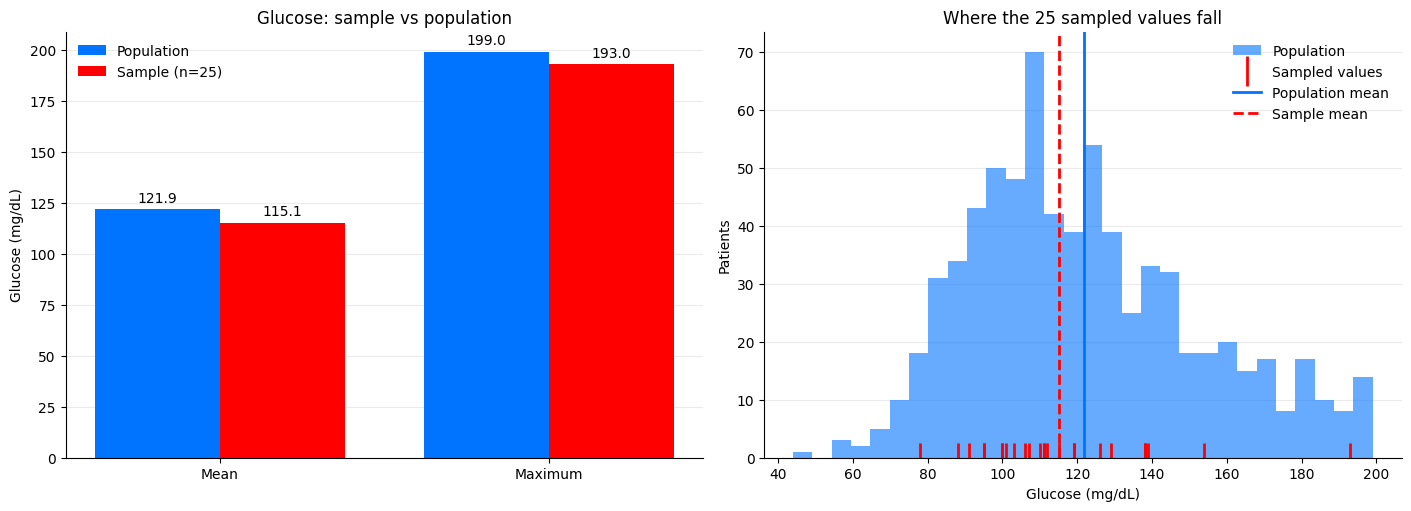

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

positions = np.arange(len(glucose_comparison))
width = 0.38
population_bars = axes[0].bar(
    positions - width / 2, glucose_comparison["population"], width,
    label="Population", color=POPULATION_COLOR,
)
sample_bars = axes[0].bar(
    positions + width / 2, glucose_comparison["sample"], width,
    label="Sample (n=25)", color=SAMPLE_COLOR,
)
axes[0].bar_label(population_bars, fmt="%.1f", padding=3)
axes[0].bar_label(sample_bars, fmt="%.1f", padding=3)
axes[0].set_xticks(positions, labels=["Mean", "Maximum"])
axes[0].set(title="Glucose: sample vs population", ylabel="Glucose (mg/dL)")
axes[0].legend(frameon=False)

axes[1].hist(population["Glucose"], bins=30, color=POPULATION_COLOR, alpha=0.6, label="Population")
axes[1].plot(
    sample_25["Glucose"], np.zeros(len(sample_25)), "|",
    color=SAMPLE_COLOR, markersize=22, markeredgewidth=2, label="Sampled values",
)
axes[1].axvline(population["Glucose"].mean(), color=POPULATION_COLOR, linewidth=2, label="Population mean")
axes[1].axvline(sample_25["Glucose"].mean(), color=SAMPLE_COLOR, linewidth=2, linestyle="--", label="Sample mean")
axes[1].set(title="Where the 25 sampled values fall", xlabel="Glucose (mg/dL)", ylabel="Patients")
axes[1].legend(frameon=False)

for ax in axes:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.savefig(OUTPUT_DIR / "a_glucose_sample_vs_population.png", dpi=150)
plt.show()

### Findings
1. The mean blood glucose level in the sample was 115.1 mg/dL, which is 6.80 mg/dL lower than the population mean of 121.90 mg/dL. The chart on the right explains the reason: 18 of the 25 sample values were below the overall mean, so the proportion of patients with low blood glucose in this specific sample was slightly higher. With only 25 observations, such a large discrepancy is within the range of normal sampling variation, amounting to approximately 1.2 standard errors.
2. The maximum value in the sample is 193 mg/dL, while the maximum value in the population is 199 mg/dL. The maximum value in the sample cannot exceed the maximum value in the population because the sample is drawn from the population. The maximum value in the sample will equal the maximum value in the population only if the sample happens to include that one most extreme patient.

## 4.Part (b)

### Find the 98th percentile of BMI 

In [15]:
bmi_p98 = pd.Series({
    "population": population["BMI"].quantile(0.98),
    "sample": sample_25["BMI"].quantile(0.98),
})

bmi_p98_comparison = pd.DataFrame({"bmi_98th_percentile": bmi_p98})
bmi_p98_comparison.loc["difference"] = bmi_p98["sample"] - bmi_p98["population"]

bmi_p98_comparison.round(2)

,bmi_98th_percentile
population,47.39
sample,46.22
difference,-1.17


In [16]:
print("Largest BMI values in the sample:")
print(sample_25["BMI"].nlargest(3).to_list())

Largest BMI values in the sample:
[46.8, 45.6, 45.3]


### Chart the comparison

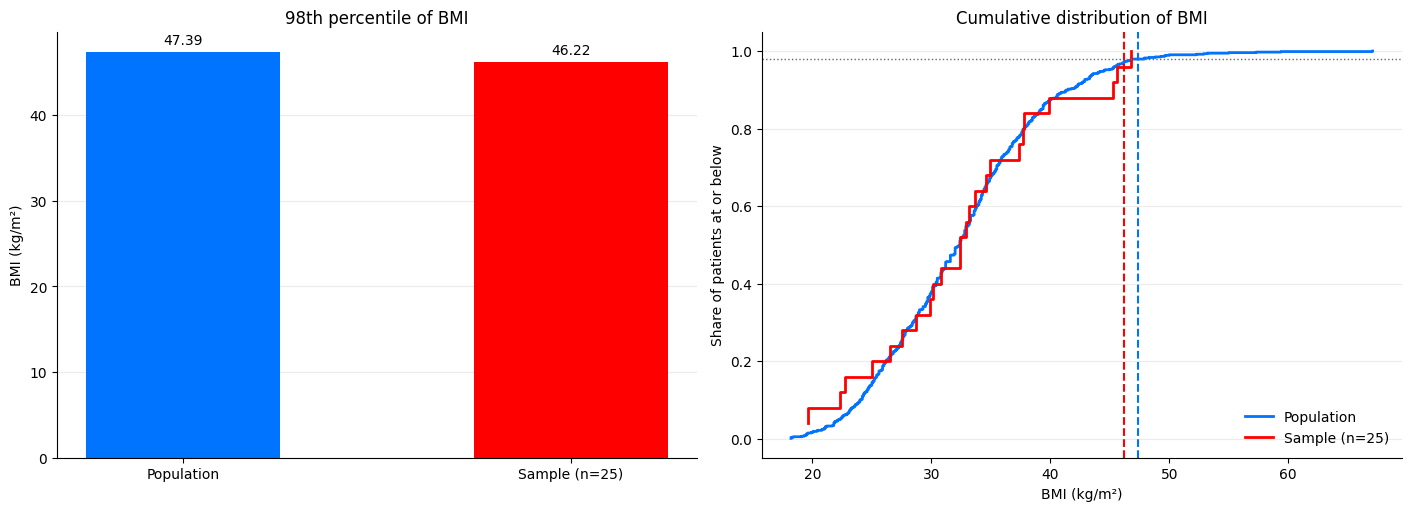

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

p98_bars = axes[0].bar(
    ["Population", "Sample (n=25)"], bmi_p98,
    color=[POPULATION_COLOR, SAMPLE_COLOR], width=0.5,
)
axes[0].bar_label(p98_bars, fmt="%.2f", padding=3)
axes[0].set(title="98th percentile of BMI", ylabel="BMI (kg/m²)")

population_bmi = np.sort(population["BMI"])
sample_bmi = np.sort(sample_25["BMI"])
axes[1].step(
    population_bmi, np.arange(1, len(population_bmi) + 1) / len(population_bmi),
    where="post", color=POPULATION_COLOR, linewidth=2, label="Population",
)
axes[1].step(
    sample_bmi, np.arange(1, len(sample_bmi) + 1) / len(sample_bmi),
    where="post", color=SAMPLE_COLOR, linewidth=2, label="Sample (n=25)",
)
axes[1].axhline(0.98, color="0.4", linewidth=1, linestyle=":")
axes[1].axvline(bmi_p98["population"], color=POPULATION_COLOR, linewidth=1.5, linestyle="--")
axes[1].axvline(bmi_p98["sample"], color=SAMPLE_COLOR, linewidth=1.5, linestyle="--")
axes[1].set(
    title="Cumulative distribution of BMI",
    xlabel="BMI (kg/m²)",
    ylabel="Share of patients at or below",
)
axes[1].legend(frameon=False, loc="lower right")

for ax in axes:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.savefig(OUTPUT_DIR / "b_bmi_98th_percentile.png", dpi=150)
plt.show()

### Findings
1. The 98th percentile for BMI in this sample was 46.22, which is slightly lower than the 47.39 for the general population, with a difference of -1.17.
2. When n = 25, the 98th percentile lies between the two largest sample values, because 0.98 * (25 − 1) = 23.52. This depends almost entirely on which one or two patients with higher BMI values happen to be included in the sample. If one more or one fewer patient with extreme values were included, this value would change significantly.
3. The chart on the right shows that the red sample curve closely follows the blue population curve in the middle portion of the distribution, but takes on a stepped appearance at the 98th percentile.

## 5. Task (c)

### Bootstrap BloodPressure

In [18]:
N_BOOTSTRAP = 500
BOOTSTRAP_SIZE = 150
PERCENTILE = 98

rng = np.random.default_rng(SEED)
blood_pressure = population["BloodPressure"]

In [19]:
bootstrap_rows = []
for _ in range(N_BOOTSTRAP):
    resample = blood_pressure.sample(n=BOOTSTRAP_SIZE, replace=True, random_state=rng)
    bootstrap_rows.append({
        "mean": resample.mean(),
        "std": resample.std(),
        "percentile": resample.quantile(PERCENTILE / 100),
    })

bootstrap_stats = pd.DataFrame(bootstrap_rows)

print("Bootstrap samples:", len(bootstrap_stats))
bootstrap_stats.head()

Bootstrap samples: 500


,mean,std,percentile
0,74.346667,11.813987,96.04
1,72.166667,11.896882,94.12
2,70.880000,12.212283,96.04
3,72.393333,13.130167,104.08
4,71.826667,11.965693,96.16


In [20]:
bootstrap_stats.describe().round(2)

,mean,std,percentile
count,500.00,500.00,500.00
mean,72.37,12.36,98.56
std,1.01,0.83,5.09
min,69.55,9.93,88.00
25%,71.70,11.76,94.08
50%,72.35,12.37,98.04
75%,73.00,12.93,102.08
max,75.23,15.15,110.00


### Compare the bootstrap averages with the population

In [21]:
bp_comparison = pd.DataFrame(
    {
        "population": [
            blood_pressure.mean(),
            blood_pressure.std(ddof=0),
            blood_pressure.quantile(PERCENTILE / 100),
        ],
        "bootstrap_average": bootstrap_stats.mean().to_list(),
        "bootstrap_spread_sd": bootstrap_stats.std().to_list(),
    },
    index=["mean", "standard deviation", f"{PERCENTILE}th percentile"],
)
bp_comparison["difference"] = bp_comparison["bootstrap_average"] - bp_comparison["population"]
bp_comparison["percent_difference"] = (
    bp_comparison["difference"] / bp_comparison["population"] * 100
)

bp_comparison = bp_comparison.round(3)
bp_comparison

,population,bootstrap_average,bootstrap_spread_sd,difference,percent_difference
mean,72.401,72.368,1.010,-0.032,-0.044
standard deviation,12.371,12.365,0.835,-0.007,-0.053
98th percentile,100.000,98.559,5.085,-1.441,-1.441


### Check the spread of the bootstrap means against theory

In [22]:
theoretical_se = blood_pressure.std(ddof=0) / np.sqrt(BOOTSTRAP_SIZE)
observed_se = bootstrap_stats["mean"].std()

print(f"Theoretical standard error: {theoretical_se:.3f} mmHg")
print(f"Observed spread of means:   {observed_se:.3f} mmHg")

Theoretical standard error: 1.010 mmHg
Observed spread of means:   1.010 mmHg


### Chart the bootstrap distributions

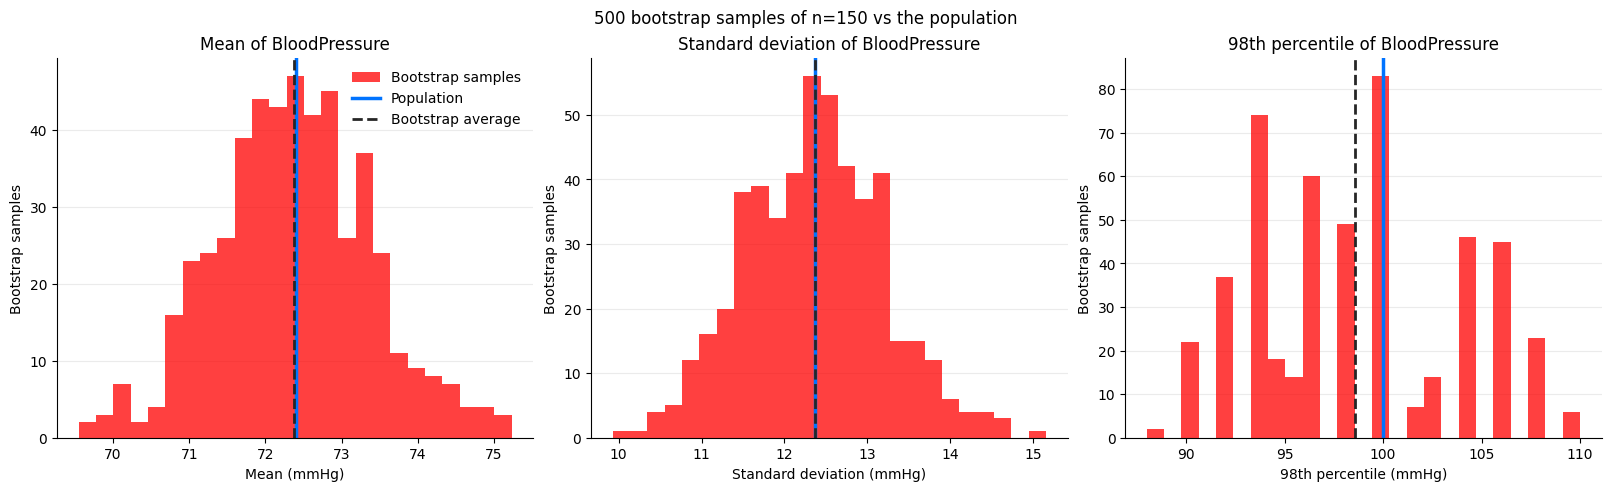

In [23]:
statistic_labels = {
    "mean": "Mean",
    "std": "Standard deviation",
    "percentile": f"{PERCENTILE}th percentile",
}
population_values = dict(zip(statistic_labels, bp_comparison["population"]))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

for ax, (column, label) in zip(axes, statistic_labels.items()):
    ax.hist(bootstrap_stats[column], bins=25, color=SAMPLE_COLOR, alpha=0.75, label="Bootstrap samples")
    ax.axvline(population_values[column], color=POPULATION_COLOR, linewidth=2.5, label="Population")
    ax.axvline(bootstrap_stats[column].mean(), color="0.15", linewidth=2, linestyle="--", label="Bootstrap average")
    ax.set(title=f"{label} of BloodPressure", xlabel=f"{label} (mmHg)", ylabel="Bootstrap samples")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].legend(frameon=False)
fig.suptitle(f"{N_BOOTSTRAP} bootstrap samples of n={BOOTSTRAP_SIZE} vs the population")

fig.savefig(OUTPUT_DIR / "c_bootstrap_distributions.png", dpi=150)
plt.show()

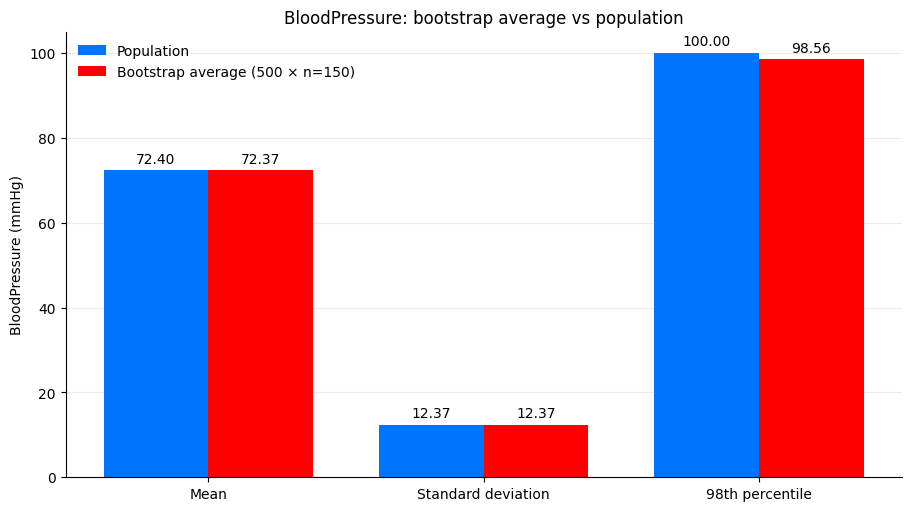

In [24]:
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)

positions = np.arange(len(bp_comparison))
width = 0.38
population_bars = ax.bar(
    positions - width / 2, bp_comparison["population"], width,
    label="Population", color=POPULATION_COLOR,
)
bootstrap_bars = ax.bar(
    positions + width / 2, bp_comparison["bootstrap_average"], width,
    label=f"Bootstrap average ({N_BOOTSTRAP} × n={BOOTSTRAP_SIZE})", color=SAMPLE_COLOR,
)
ax.bar_label(population_bars, fmt="%.2f", padding=3)
ax.bar_label(bootstrap_bars, fmt="%.2f", padding=3)
ax.set_xticks(positions, labels=bp_comparison.index.str.capitalize())
ax.set(title="BloodPressure: bootstrap average vs population", ylabel="BloodPressure (mmHg)")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.savefig(OUTPUT_DIR / "c_bootstrap_vs_population.png", dpi=150)
plt.show()

#### Findings

1. The mean was reproduced with the perfect accuracy. The deviation between the average of the 500 means obtained using the self-sampling method and the population mean was within 0.03 mmHg. The individual means ranged from 69.55 to 75.23, and their coefficient of variation (1.010 mmHg) was consistent with the theoretical standard error of 1.010. The self-sampling method reproduced the sampling distribution predicted by theory.
2. The standard deviation was also estimated with very high accuracy. Each resampling used the sampling formula ddof=1, which is unbiased with respect to the population variance. The mean obtained using the guided method differed from the population variance by only 0.01 mmHg. The results of each resampling still fell within the range of 9.93 to 15.15 mmHg.
3. The 98th percentile is not a reliable statistical measure. Its self-calculated mean (98.56) is 1.44 mmHg lower than the population mean, and there is considerable variation among the estimates (standard deviation 5.09, range 88-110). Becasue among the 150 observations, the 98th percentile is based solely on the first three values obtained from each resampling. Whether those rare, highest readings are included has a significant impact on the value; if they are not included, the value decreases. In addition, blood pressure is typically recorded as an even integer, so the percentile can only take on a few different values.
4. By averaging across many bootstrap samples, it is possible to estimate the center, mean, and standard deviation with high precision. Statistics at the tails of the distribution converge more slowly. To estimate extreme quantiles with the same precision as the mean, a larger number of bootstrap samples is required.

## 6. Export

In [25]:
glucose_comparison.to_csv(OUTPUT_DIR / "a_glucose_comparison.csv")
bmi_p98_comparison.to_csv(OUTPUT_DIR / "b_bmi_p98_comparison.csv")
bp_comparison.to_csv(OUTPUT_DIR / "c_bloodpressure_comparison.csv")
bootstrap_stats.to_csv(OUTPUT_DIR / "c_bootstrap_statistics.csv", index=False)

for path in sorted(OUTPUT_DIR.iterdir()):
    print("Exported:", path.resolve())

Exported: D:\Assignment_2\Q2\output\a_glucose_comparison.csv
Exported: D:\Assignment_2\Q2\output\a_glucose_sample_vs_population.png
Exported: D:\Assignment_2\Q2\output\b_bmi_98th_percentile.png
Exported: D:\Assignment_2\Q2\output\b_bmi_p98_comparison.csv
Exported: D:\Assignment_2\Q2\output\c_bloodpressure_comparison.csv
Exported: D:\Assignment_2\Q2\output\c_bootstrap_distributions.png
Exported: D:\Assignment_2\Q2\output\c_bootstrap_statistics.csv
Exported: D:\Assignment_2\Q2\output\c_bootstrap_vs_population.png
